# FarmTech Solutions — Fase 3, Capítulo 11

## Análise exploratória e comparação de modelos de classificação

**Gabriel Tamais Fischer · RM 574503**

Este relatório usa exclusivamente o CSV oficial incluído em `cap11/data/Atividade_Cap11_produtos_agricolas.csv`. Ele reúne a análise exploratória, a comparação de três culturas e a avaliação dos cinco classificadores solicitados. As conclusões descrevem este dataset e não substituem validação agronômica em campo.

## Resumo

As conclusões e o ranking são preenchidos a partir das execuções abaixo. Todas as métricas dos algoritmos usam as mesmas partições e folds; a escolha final do modelo considera a tabela comparativa produzida com dados observados.

## 1. Fonte, schema e preparação

`modelagem.py` contém o contrato comum do projeto. O CSV original não é alterado. A coluna `pH`, quando presente, é normalizada pela função compartilhada para `ph`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

cwd = Path.cwd()
CAP11_DIR = next(p for p in (cwd / "cap11", cwd) if (p / "modelagem.py").is_file())
if str(CAP11_DIR) not in sys.path:
    sys.path.insert(0, str(CAP11_DIR))

from modelagem import (FEATURES, TARGET, RANDOM_STATE, METRICS, EXPECTED_MODELS,
                       carregar_dataset, separar_treino_teste, construir_pipeline,
                       criar_validacao_cruzada, criar_tabela_comparacao,
                       configurar_estilo_graficos)

configurar_estilo_graficos()
CSV_PATH = CAP11_DIR / "data" / "Atividade_Cap11_produtos_agricolas.csv"
dados = carregar_dataset(CSV_PATH)
print(f"Fonte: {CSV_PATH}")
print(f"Dimensões: {dados.shape[0]} linhas × {dados.shape[1]} colunas")
print("Colunas:", dados.columns.tolist())
display(dados.dtypes.rename("tipo").to_frame())
display(dados.isna().sum().rename("ausentes").to_frame())
print("Duplicatas completas:", int(dados.duplicated().sum()))
print("Culturas:", dados[TARGET].nunique())
display(dados[TARGET].value_counts().sort_index().rename("registros").to_frame())
display(dados.head())
assert dados.columns.tolist() == FEATURES + [TARGET]
assert not dados.empty and not dados.isna().any().any()

Fonte: cap11/data/Atividade_Cap11_produtos_agricolas.csv
Dimensões: 2200 linhas × 8 colunas
Colunas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,tipo
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str


,ausentes
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


Duplicatas completas: 0
Culturas: 22


,registros
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Análise exploratória

As figuras mostram a distribuição das classes, as distribuições das variáveis, correlações entre atributos e diferenças entre culturas. Correlação descreve associação linear e não demonstra causalidade.

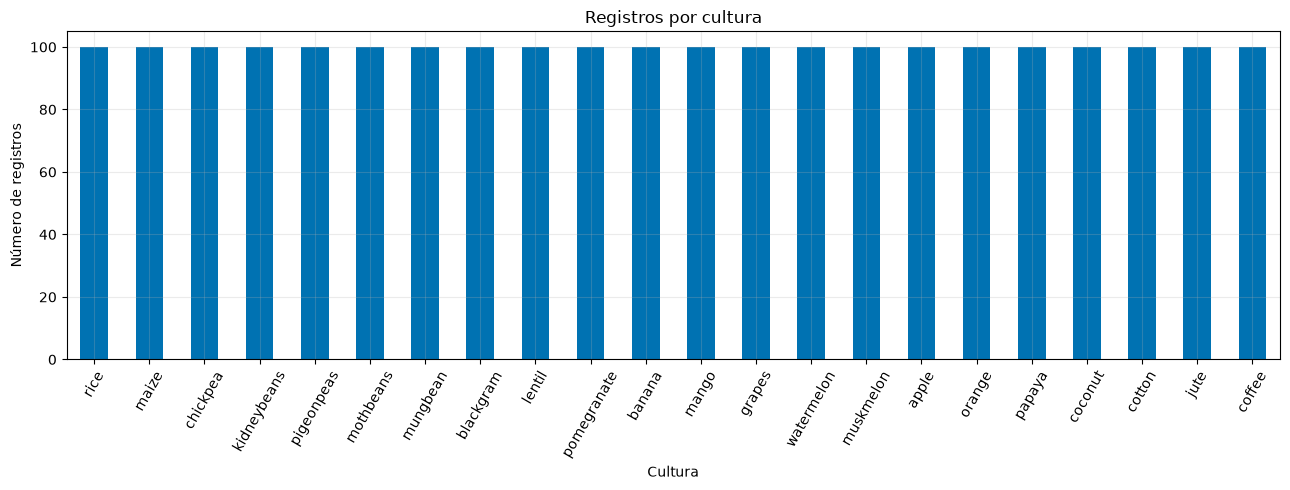

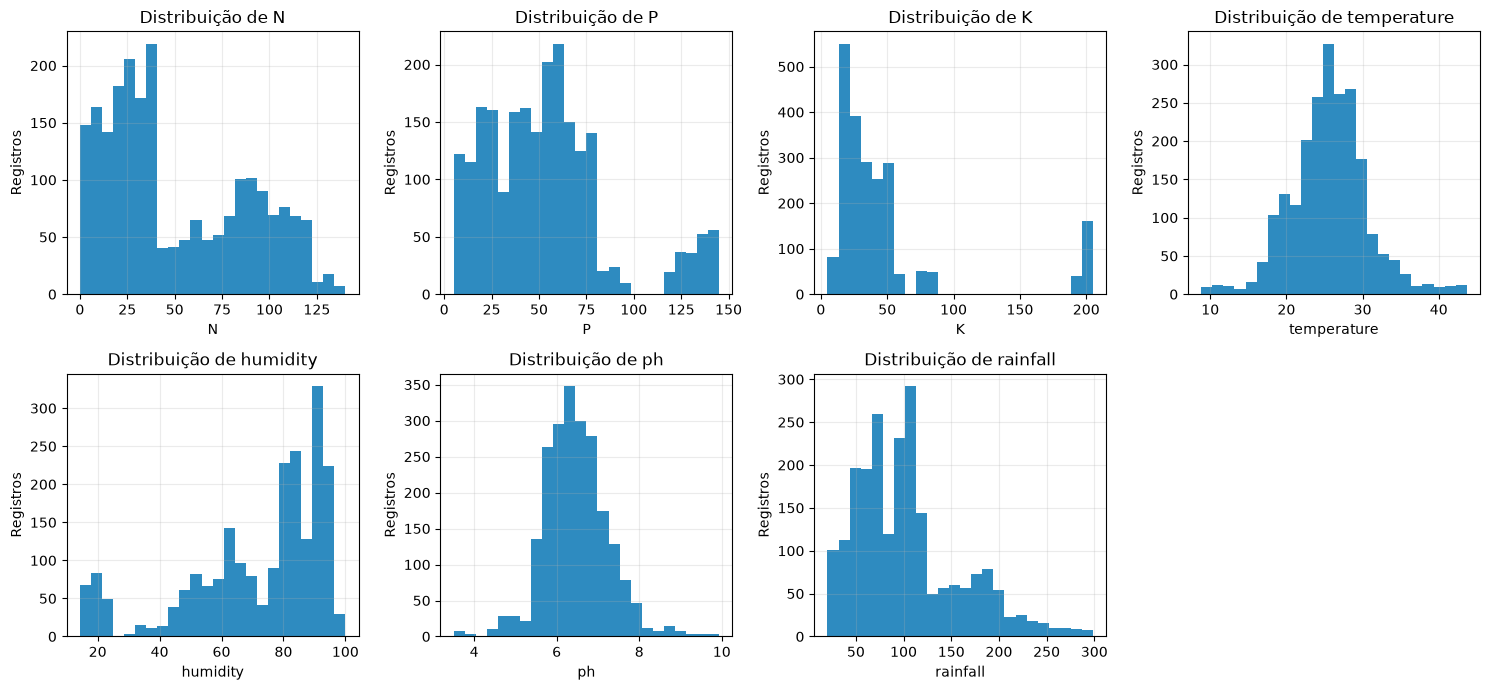

In [2]:
# Gráfico 1 — quantidade de registros por cultura
fig, ax = plt.subplots(figsize=(13, 5))
ordem = dados[TARGET].value_counts().sort_values(ascending=False).index
dados[TARGET].value_counts().reindex(ordem).plot(kind="bar", ax=ax, color="#0072B2")
ax.set(title="Registros por cultura", xlabel="Cultura", ylabel="Número de registros")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout(); plt.show()

# Gráfico 2 — distribuição de cada variável numérica
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(dados[col], bins=24, color="#0072B2", alpha=0.82)
    ax.set_title(f"Distribuição de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Registros")
axes.flat[-1].axis("off")
fig.tight_layout(); plt.show()

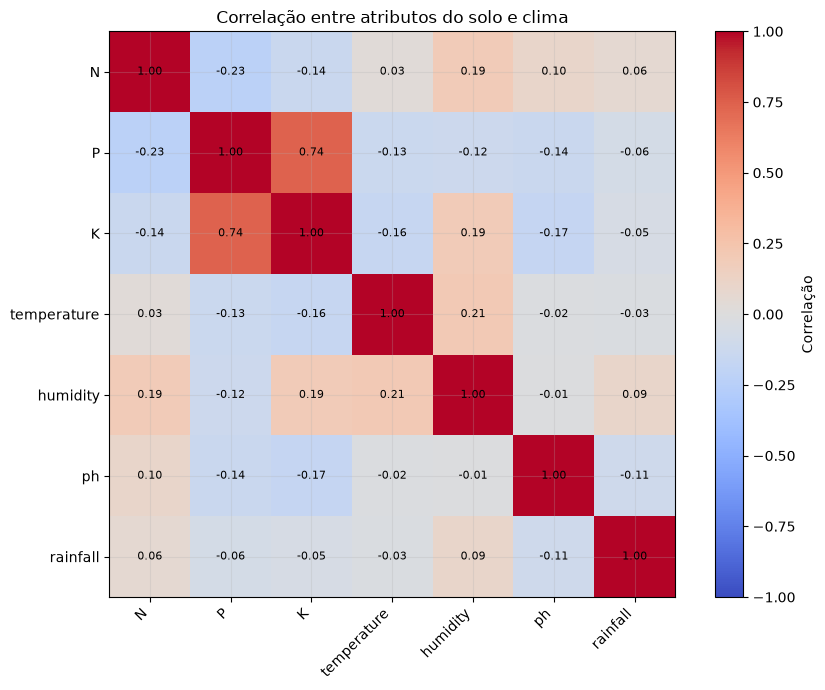

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.552,36.917,0.000,21.000,37.000,84.250,140.000
P,2200.0,53.363,32.986,5.000,28.000,51.000,68.000,145.000
K,2200.0,48.149,50.648,5.000,20.000,32.000,49.000,205.000
temperature,2200.0,25.616,5.064,8.826,22.769,25.599,28.562,43.675
humidity,2200.0,71.482,22.264,14.258,60.262,80.473,89.949,99.982
ph,2200.0,6.469,0.774,3.505,5.972,6.425,6.924,9.935
rainfall,2200.0,103.464,54.958,20.211,64.552,94.868,124.268,298.560


In [3]:
# Gráfico 3 — correlação entre variáveis numéricas
corr = dados[FEATURES].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlação")
ax.set_title("Correlação entre atributos do solo e clima")
fig.tight_layout(); plt.show()

display(dados[FEATURES].describe().T.round(3))

In [4]:
# Achados descritivos calculados diretamente da base
contagens = dados[TARGET].value_counts()
corr_abs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().abs().sort_values(ascending=False)
par_corr = corr_abs.index[0]
display(Markdown(
    f"A base contém **{dados.shape[0]:,} registros**, **{dados[TARGET].nunique()} culturas** e "
    f"**{contagens.min()} registros por classe** (mínimo) até **{contagens.max()}** (máximo), "
    f"portanto as classes estão balanceadas. Entre os atributos numéricos, a maior correlação linear "
    f"absoluta observada foi entre **{par_corr[0]}** e **{par_corr[1]}** "
    f"(r = {corr.loc[par_corr[0], par_corr[1]]:.3f}). A associação é descritiva e não implica causalidade."
))

A base contém **2,200 registros**, **22 culturas** e **100 registros por classe** (mínimo) até **100** (máximo), portanto as classes estão balanceadas. Entre os atributos numéricos, a maior correlação linear absoluta observada foi entre **P** e **K** (r = 0.736). A associação é descritiva e não implica causalidade.

## 3. Perfil de referência e três culturas

Como o CSV não contém produtividade, rendimento, qualidade da colheita nem um indicador de sucesso agronômico, não é possível estimar um ótimo causal ou universal. Para atender à comparação, definimos explicitamente um **perfil ideal de referência empírico**: a mediana global das condições rotuladas no dataset. Ele descreve o centro das observações associadas às culturas deste arquivo; é uma referência estatística, não uma recomendação de plantio. As três culturas selecionadas são comparadas a essa referência usando medianas por cultura, desvios padronizados e distribuições.

,mediana global,chickpea,maize,rice
N,37.000,39.000,76.000,80.000
P,51.000,68.000,48.500,47.000
K,32.000,79.000,20.000,40.000
temperature,25.599,18.878,22.844,23.735
humidity,80.473,16.659,65.304,82.189
ph,6.425,7.357,6.259,6.364
rainfall,94.868,79.692,83.472,233.120


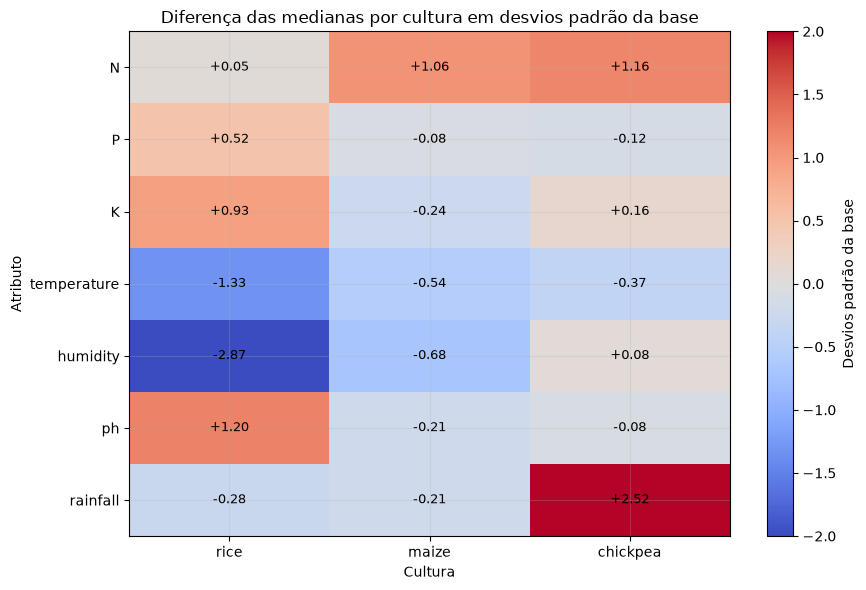

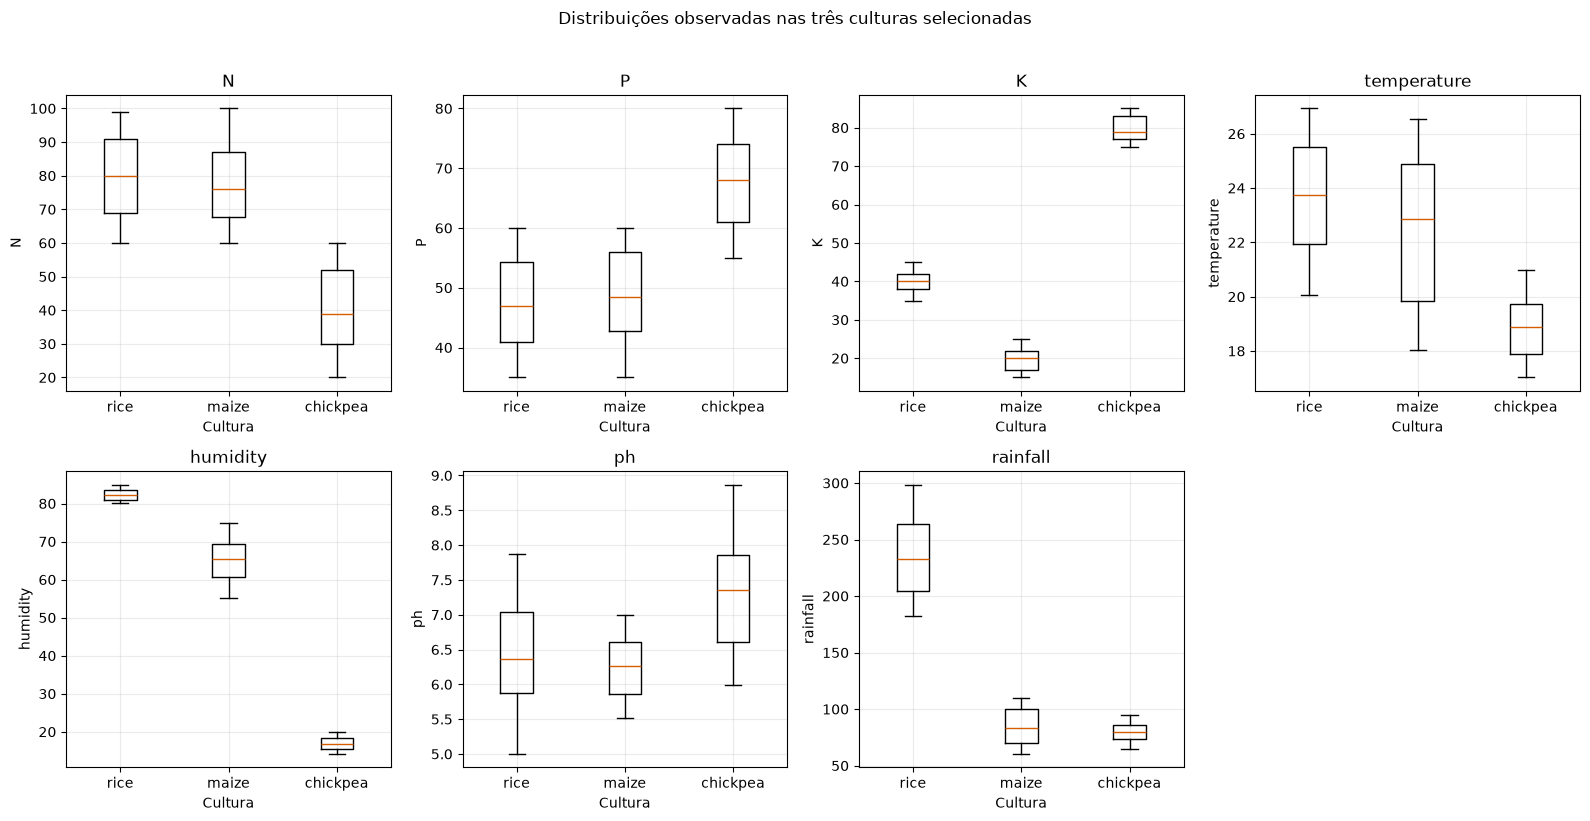

rice: 100 registros; maiores desvios: rainfall (rainfall acima), N (N acima), K (K acima)
maize: 100 registros; maiores desvios: N (N acima), humidity (humidity abaixo), K (K abaixo)
chickpea: 100 registros; maiores desvios: humidity (humidity abaixo), K (K acima), P (P acima)


In [5]:
# Seleção fixa de culturas existentes no dataset
CULTURAS = ["rice", "maize", "chickpea"]
assert set(CULTURAS).issubset(set(dados[TARGET].unique()))
perfil_referencia = dados[FEATURES].median()
perfis_culturas = dados[dados[TARGET].isin(CULTURAS)].groupby(TARGET)[FEATURES].median().T
resumo_perfis = pd.concat([perfil_referencia.rename("mediana global"), perfis_culturas], axis=1)
display(resumo_perfis.round(3))

# Gráfico 4 — medianas padronizadas para visualizar desvios relativos
desvios = (perfis_culturas - perfil_referencia,)
escala = dados[FEATURES].std(ddof=1).replace(0, 1)
desvios_padronizados = (perfis_culturas.subtract(perfil_referencia, axis=0)
                        .div(escala, axis=0))
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(desvios_padronizados, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(CULTURAS)), CULTURAS)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(CULTURAS)):
        ax.text(j, i, f"{desvios_padronizados.iloc[i,j]:+.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Desvios padrão da base")
ax.set_title("Diferença das medianas por cultura em desvios padrão da base")
ax.set_xlabel("Cultura"); ax.set_ylabel("Atributo")
fig.tight_layout(); plt.show()

# Gráfico 5 — distribuições das variáveis para as três culturas
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, FEATURES):
    amostras = [dados.loc[dados[TARGET] == cultura, col].to_numpy() for cultura in CULTURAS]
    ax.boxplot(amostras, tick_labels=CULTURAS, showfliers=False)
    ax.set_title(col); ax.set_xlabel("Cultura"); ax.set_ylabel(col)
axes.flat[-1].axis("off")
fig.suptitle("Distribuições observadas nas três culturas selecionadas", y=1.02)
fig.tight_layout(); plt.show()

# Diferenças descritivas calculadas a partir dos dados reais
for cultura in CULTURAS:
    perfil = perfis_culturas[cultura]
    maior = (perfil - perfil_referencia).abs().sort_values(ascending=False).head(3).index.tolist()
    direcoes = [f"{v} acima" if perfil[v] > perfil_referencia[v] else f"{v} abaixo" for v in maior]
    print(f"{cultura}: {len(dados[dados.label == cultura])} registros; maiores desvios: " + ", ".join(f"{v} ({d})" for v,d in zip(maior,direcoes)))

In [6]:
linhas_perfil = []
for cultura in CULTURAS:
    perfil = perfis_culturas[cultura]
    diferencas = perfil - perfil_referencia
    destacados = diferencas.abs().sort_values(ascending=False).head(3).index
    frases = [f"{v}: {perfil[v]:.2f} vs referência {perfil_referencia[v]:.2f} ({'acima' if diferencas[v] > 0 else 'abaixo'})" for v in destacados]
    linhas_perfil.append(f"- **{cultura}**: " + "; ".join(frases) + ".")
display(Markdown(
    "Comparação das medianas por cultura com a referência empírica (valores e direções calculados da base):\n\n"
    + "\n".join(linhas_perfil)
    + "\n\nEssas diferenças descrevem as observações rotuladas no CSV e não significam que aproximar uma cultura da mediana global aumentaria seu rendimento."
))

Comparação das medianas por cultura com a referência empírica (valores e direções calculados da base):

- **rice**: rainfall: 233.12 vs referência 94.87 (acima); N: 80.00 vs referência 37.00 (acima); K: 40.00 vs referência 32.00 (acima).
- **maize**: N: 76.00 vs referência 37.00 (acima); humidity: 65.30 vs referência 80.47 (abaixo); K: 20.00 vs referência 32.00 (abaixo).
- **chickpea**: humidity: 16.66 vs referência 80.47 (abaixo); K: 79.00 vs referência 32.00 (acima); P: 68.00 vs referência 51.00 (acima).

Essas diferenças descrevem as observações rotuladas no CSV e não significam que aproximar uma cultura da mediana global aumentaria seu rendimento.

## 4. Preparação comum do problema

`separar_treino_teste` é chamado uma vez para criar a partição compartilhada. O split é estratificado, usa 20% para teste e `random_state=42`. O scaler permanece dentro de cada pipeline e é ajustado somente nos dados de treino de cada fold. Não há sobreposição de índices entre treino e teste.

In [7]:
particoes = separar_treino_teste(dados, random_state=RANDOM_STATE)
X_train, X_test = particoes.X_train, particoes.X_test
y_train, y_test = particoes.y_train, particoes.y_test
print(f"Treino: {len(X_train)} | teste: {len(X_test)}")
print("Features:", list(X_train.columns), "| target:", TARGET)
print("Índices sobrepostos:", bool(set(X_train.index) & set(X_test.index)))
assert list(X_train.columns) == FEATURES and TARGET not in X_train.columns
assert not (set(X_train.index) & set(X_test.index))
assert X_test.index.equals(separar_treino_teste(dados).X_test.index)

Treino: 1760 | teste: 440
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'] | target: label
Índices sobrepostos: False


## 5. Validação cruzada no treino

Os cinco algoritmos recebem os mesmos dados de treino, o mesmo splitter e as mesmas cinco métricas. O conjunto de teste não participa da validação cruzada nem da escolha de configuração.

In [8]:
MODELOS = {
    "Árvore de Decisão": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Regressão Logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "SVM": SVC(kernel="rbf", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
assert list(MODELOS) == EXPECTED_MODELS
SCORING = {"accuracy":"accuracy", "precision_macro":"precision_macro",
           "recall_macro":"recall_macro", "f1_macro":"f1_macro"}
pipelines = {nome: construir_pipeline(est) for nome, est in MODELOS.items()}
cv_resultados = {}
for nome, pipeline in pipelines.items():
    cv_resultados[nome] = cross_validate(
        pipeline, X_train, y_train,
        cv=criar_validacao_cruzada(), scoring=SCORING,
        return_train_score=False, n_jobs=1,
    )
linhas_cv = []
for nome, resultado in cv_resultados.items():
    linha = {"Modelo": nome}
    for metrica in METRICS:
        valores = resultado[f"test_{metrica}"]
        linha[f"{metrica} média"] = valores.mean()
        linha[f"{metrica} DP"] = valores.std(ddof=1)
    linhas_cv.append(linha)
tabela_cv = pd.DataFrame(linhas_cv).set_index("Modelo")
display(tabela_cv.style.format("{:.4f}"))

,accuracy média,accuracy DP,precision_macro média,precision_macro DP,recall_macro média,recall_macro DP,f1_macro média,f1_macro DP
Modelo,,,,,,,,
Árvore de Decisão,0.9852,0.0076,0.9863,0.0071,0.9852,0.0076,0.9852,0.0076
Regressão Logística,0.9682,0.0074,0.9710,0.0066,0.9682,0.0074,0.9678,0.0076
Random Forest,0.9932,0.0059,0.9939,0.0050,0.9932,0.0059,0.9931,0.0059
SVM,0.9790,0.0115,0.9822,0.0090,0.9790,0.0115,0.9788,0.0119
Gradient Boosting,0.9869,0.0038,0.9881,0.0033,0.9869,0.0038,0.9869,0.0040


## 6. Ajuste final e métricas no teste

Cada pipeline é ajustado no treino completo e avaliado uma única vez no teste compartilhado. Precision, Recall e F1 usam média macro para dar peso igual às culturas. A comparação abaixo usa resultados medidos neste dataset; não inventa métricas ausentes.

In [9]:
def calcular_metricas(y_real, y_previsto):
    return {
        "accuracy": accuracy_score(y_real, y_previsto),
        "precision_macro": precision_score(y_real, y_previsto, average="macro", zero_division=0),
        "recall_macro": recall_score(y_real, y_previsto, average="macro", zero_division=0),
        "f1_macro": f1_score(y_real, y_previsto, average="macro", zero_division=0),
    }

metricas_teste, metricas_treino, previsoes, matrizes = {}, {}, {}, {}
ordem_classes = sorted(dados[TARGET].unique())
for nome, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_hat = pipeline.predict(X_test)
    previsoes[nome] = y_hat
    metricas_teste[nome] = calcular_metricas(y_test, y_hat)
    metricas_treino[nome] = calcular_metricas(y_train, pipeline.predict(X_train))
    matrizes[nome] = confusion_matrix(y_test, y_hat, labels=ordem_classes)

tabela_teste = pd.DataFrame(metricas_teste).T
tabela_teste.index.name = "Modelo"
tabela_teste = tabela_teste.sort_values("f1_macro", ascending=False)
display(tabela_teste.style.format("{:.4f}"))
assert all(matriz.shape == (len(ordem_classes), len(ordem_classes)) and matriz.sum() == len(y_test)
           for matriz in matrizes.values())
assert all(0 <= v <= 1 for metricas in metricas_teste.values() for v in metricas.values())
assert all(len(p) == len(y_test) for p in previsoes.values())

,accuracy,precision_macro,recall_macro,f1_macro
Modelo,,,,
Random Forest,0.9955,0.9957,0.9955,0.9955
Gradient Boosting,0.9886,0.9897,0.9886,0.9887
SVM,0.9841,0.9856,0.9841,0.9840
Árvore de Decisão,0.9795,0.9806,0.9795,0.9794
Regressão Logística,0.9727,0.9740,0.9727,0.9725


In [10]:
pontos_fortes_limitacoes = {
    "Árvore de Decisão": ("regras interpretáveis e relações não lineares", "árvore única pode variar com a amostra e sobreajustar"),
    "Regressão Logística": ("baseline eficiente e coeficientes inspecionáveis", "fronteiras lineares podem não capturar interações complexas"),
    "Random Forest": ("ensemble de árvores robusto a não linearidades", "menor transparência e importância por impureza pode favorecer atributos com mais cortes"),
    "SVM": ("kernel RBF representa fronteiras não lineares", "mais difícil de interpretar e depende de escala e hiperparâmetros"),
    "Gradient Boosting": ("combina árvores sequencialmente para corrigir erros", "sensível à configuração e pode sobreajustar"),
}
for nome in EXPECTED_MODELS:
    cv_f1 = cv_resultados[nome]["test_f1_macro"]
    gap = metricas_treino[nome]["f1_macro"] - metricas_teste[nome]["f1_macro"]
    matriz = matrizes[nome]
    pares = [(int(matriz[i,j]), ordem_classes[i], ordem_classes[j])
             for i in range(len(ordem_classes)) for j in range(len(ordem_classes))
             if i != j and matriz[i,j] > 0]
    confusao = max(pares, default=None)
    resumo_erro = (f"Maior confusão observada: {confusao[1]} prevista como {confusao[2]} ({confusao[0]} caso(s))."
                   if confusao else "Não houve erros de classificação no teste.")
    forte, limite = pontos_fortes_limitacoes[nome]
    display(Markdown(
        f"### {nome} — interpretação\n\n"
        f"No teste, Accuracy = **{metricas_teste[nome]['accuracy']:.4f}**, "
        f"Precision macro = **{metricas_teste[nome]['precision_macro']:.4f}**, "
        f"Recall macro = **{metricas_teste[nome]['recall_macro']:.4f}** e "
        f"F1 macro = **{metricas_teste[nome]['f1_macro']:.4f}**. "
        f"Na CV, F1 macro médio = **{cv_f1.mean():.4f}** (DP {cv_f1.std(ddof=1):.4f}); "
        f"gap F1 treino-teste = **{gap:.4f}**. {resumo_erro}\n\n"
        f"**Ponto forte:** {forte}. **Limitação:** {limite}."
    ))

### Árvore de Decisão — interpretação

No teste, Accuracy = **0.9795**, Precision macro = **0.9806**, Recall macro = **0.9795** e F1 macro = **0.9794**. Na CV, F1 macro médio = **0.9852** (DP 0.0076); gap F1 treino-teste = **0.0206**. Maior confusão observada: lentil prevista como mothbeans (2 caso(s)).

**Ponto forte:** regras interpretáveis e relações não lineares. **Limitação:** árvore única pode variar com a amostra e sobreajustar.

### Regressão Logística — interpretação

No teste, Accuracy = **0.9727**, Precision macro = **0.9740**, Recall macro = **0.9727** e F1 macro = **0.9725**. Na CV, F1 macro médio = **0.9678** (DP 0.0076); gap F1 treino-teste = **0.0014**. Maior confusão observada: rice prevista como jute (4 caso(s)).

**Ponto forte:** baseline eficiente e coeficientes inspecionáveis. **Limitação:** fronteiras lineares podem não capturar interações complexas.

### Random Forest — interpretação

No teste, Accuracy = **0.9955**, Precision macro = **0.9957**, Recall macro = **0.9955** e F1 macro = **0.9955**. Na CV, F1 macro médio = **0.9931** (DP 0.0059); gap F1 treino-teste = **0.0045**. Maior confusão observada: rice prevista como jute (1 caso(s)).

**Ponto forte:** ensemble de árvores robusto a não linearidades. **Limitação:** menor transparência e importância por impureza pode favorecer atributos com mais cortes.

### SVM — interpretação

No teste, Accuracy = **0.9841**, Precision macro = **0.9856**, Recall macro = **0.9841** e F1 macro = **0.9840**. Na CV, F1 macro médio = **0.9788** (DP 0.0119); gap F1 treino-teste = **0.0018**. Maior confusão observada: rice prevista como jute (3 caso(s)).

**Ponto forte:** kernel RBF representa fronteiras não lineares. **Limitação:** mais difícil de interpretar e depende de escala e hiperparâmetros.

### Gradient Boosting — interpretação

No teste, Accuracy = **0.9886**, Precision macro = **0.9897**, Recall macro = **0.9886** e F1 macro = **0.9887**. Na CV, F1 macro médio = **0.9869** (DP 0.0040); gap F1 treino-teste = **0.0113**. Maior confusão observada: rice prevista como jute (2 caso(s)).

**Ponto forte:** combina árvores sequencialmente para corrigir erros. **Limitação:** sensível à configuração e pode sobreajustar.

## 7. Matrizes de confusão e erros principais

Cada matriz tem linhas para a cultura real e colunas para a previsão. As contagens fora da diagonal mostram quais classes foram confundidas. A tabela resume os pares de erro mais frequentes por modelo.

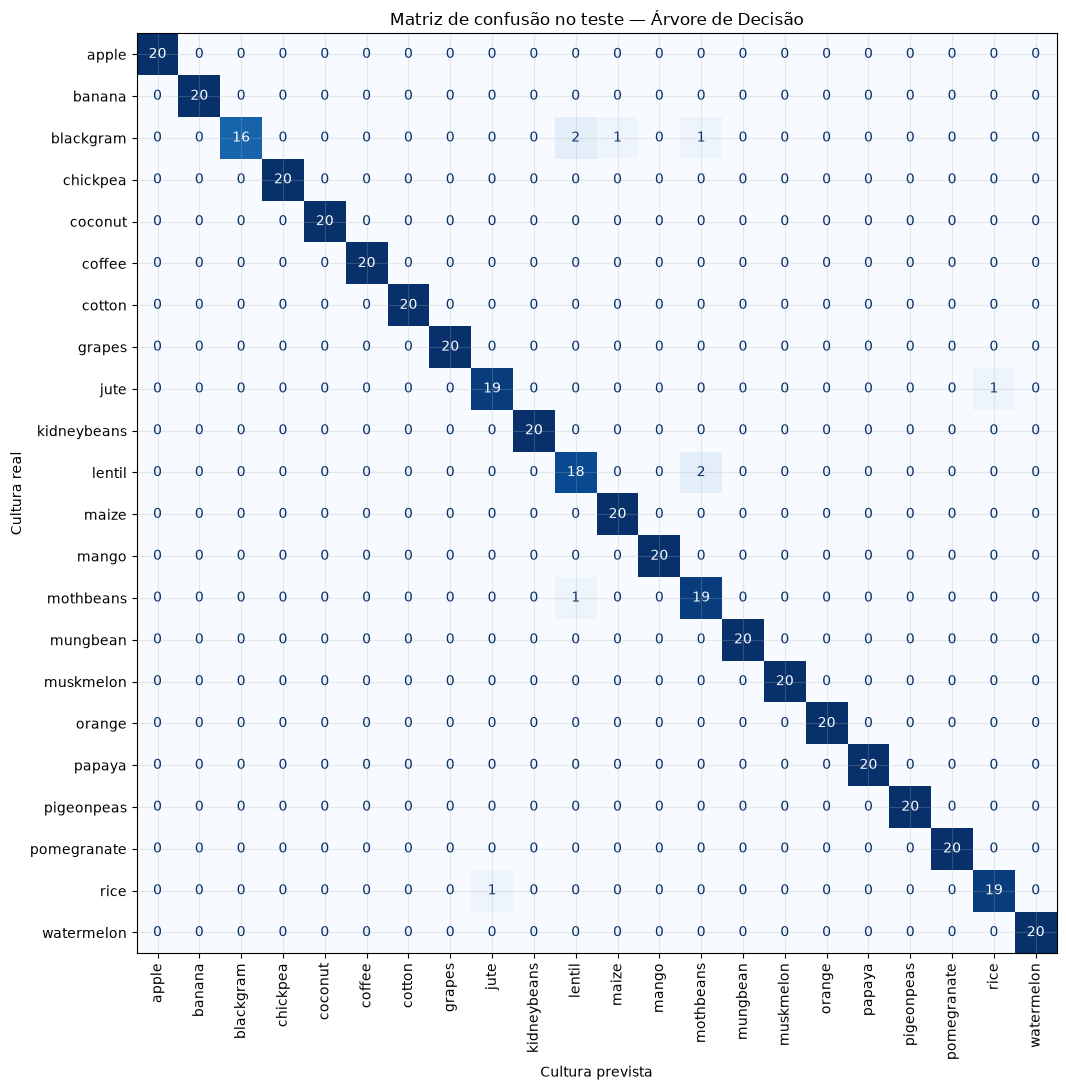

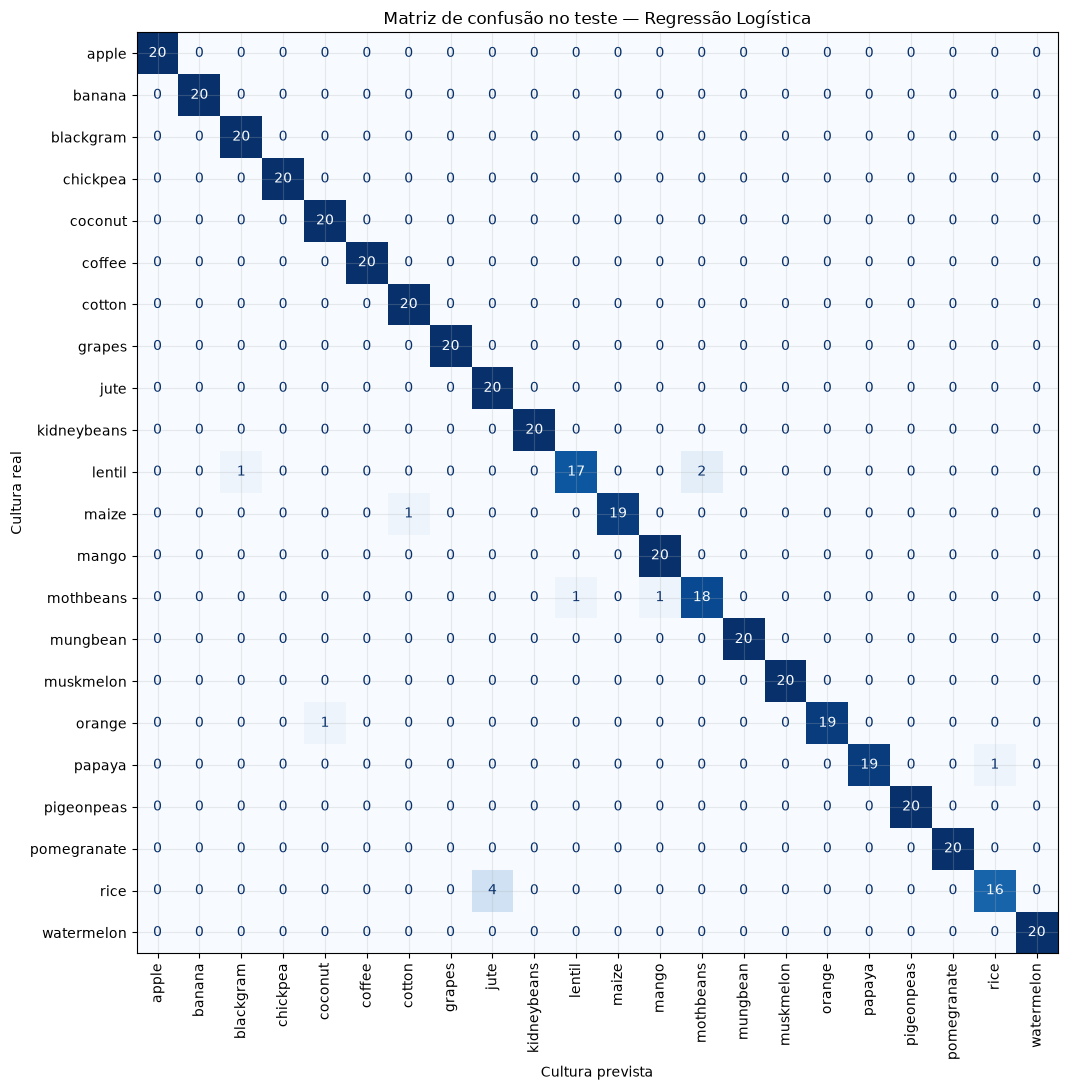

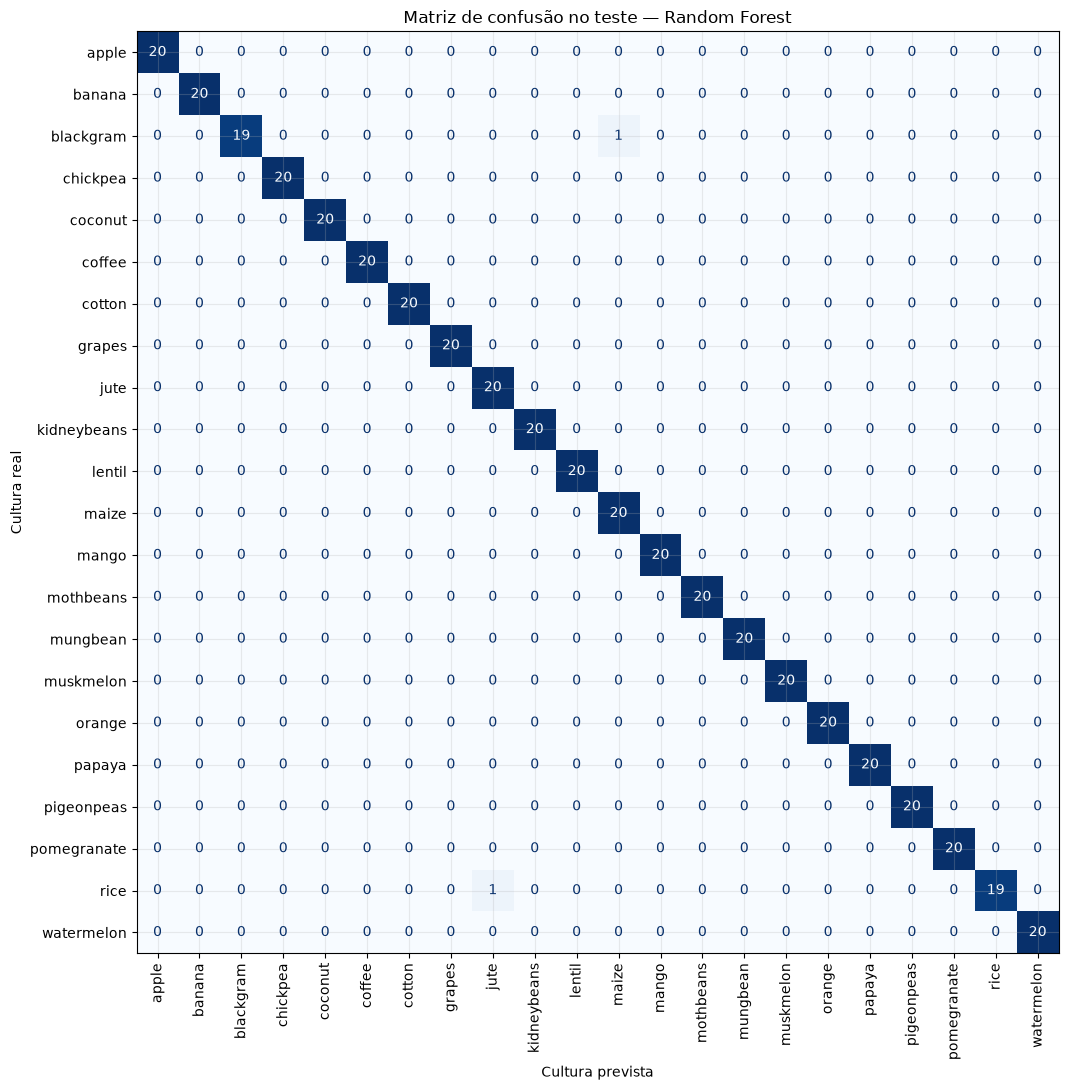

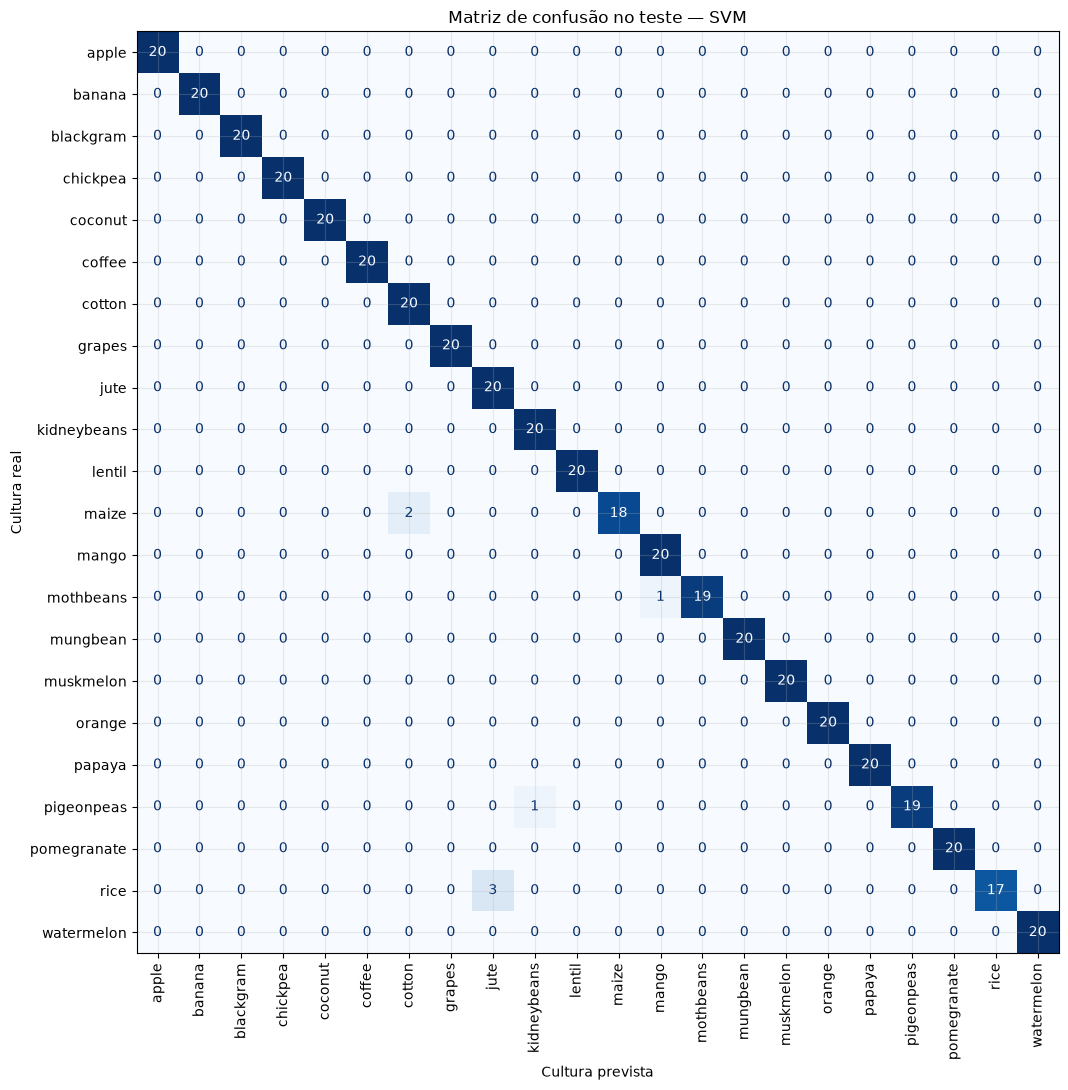

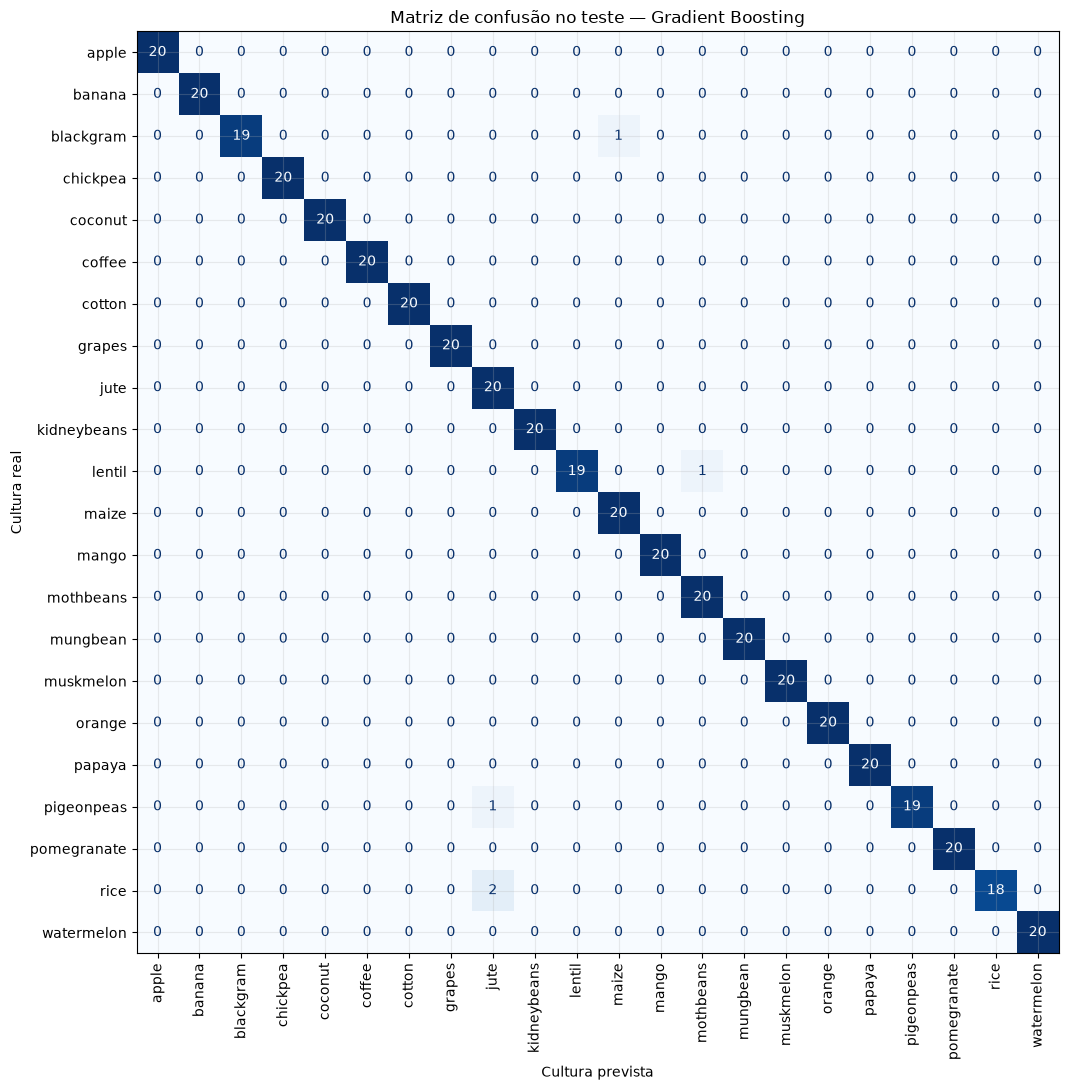

,Modelo,Cultura real,Prevista como,Casos
0,Árvore de Decisão,lentil,mothbeans,2
1,Árvore de Decisão,blackgram,lentil,2
2,Árvore de Decisão,rice,jute,1
3,Regressão Logística,rice,jute,4
4,Regressão Logística,lentil,mothbeans,2
5,Regressão Logística,papaya,rice,1
6,Random Forest,rice,jute,1
7,Random Forest,blackgram,maize,1
8,SVM,rice,jute,3
9,SVM,maize,cotton,2


In [11]:
for nome in MODELOS:
    fig, ax = plt.subplots(figsize=(13, 11))
    ConfusionMatrixDisplay(matrizes[nome], display_labels=ordem_classes).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=90)
    ax.set_title(f"Matriz de confusão no teste — {nome}")
    ax.set_xlabel("Cultura prevista")
    ax.set_ylabel("Cultura real")
    fig.tight_layout(); plt.show()

linhas_erros = []
for nome, matriz in matrizes.items():
    pares = sorted([(int(matriz[i,j]), ordem_classes[i], ordem_classes[j])
                    for i in range(len(ordem_classes)) for j in range(len(ordem_classes))
                    if i != j and matriz[i,j] > 0], reverse=True)[:3]
    for n, real, previsto in pares:
        linhas_erros.append({"Modelo":nome,"Cultura real":real,"Prevista como":previsto,"Casos":n})
display(pd.DataFrame(linhas_erros))

## 8. Overfitting e importância de atributos

O gap entre F1 de treino e teste é um indicador simples de possível overfitting. A validação cruzada ajuda a avaliar variação entre folds. Importância por impureza está disponível para árvores e ensembles; regressão logística permite inspecionar coeficientes. O SVM com kernel RBF não expõe uma importância direta comparável, por isso não será atribuída importância artificial.

,F1 treino,F1 teste,Gap treino − teste,F1 CV média,F1 CV DP
Árvore de Decisão,1.0000,0.9794,0.0206,0.9852,0.0076
Gradient Boosting,1.0000,0.9887,0.0113,0.9869,0.0040
Random Forest,1.0000,0.9955,0.0045,0.9931,0.0059
SVM,0.9858,0.9840,0.0018,0.9788,0.0119
Regressão Logística,0.9738,0.9725,0.0014,0.9678,0.0076


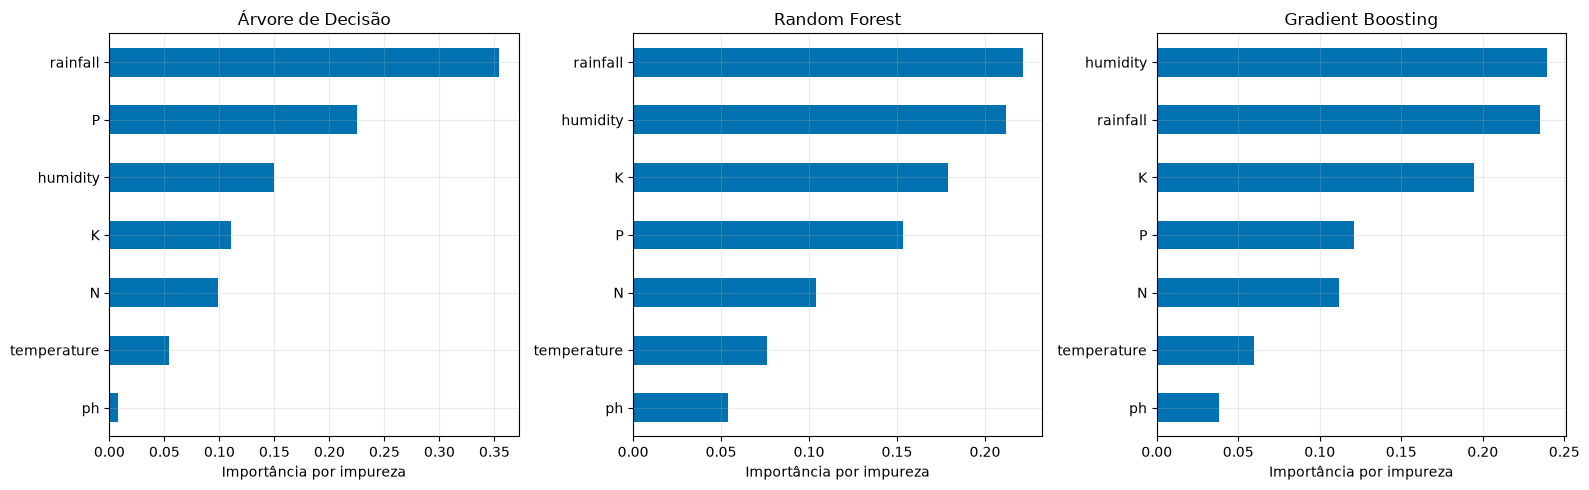

,média da magnitude absoluta dos coeficientes
humidity,2.0763
rainfall,2.0073
P,1.8731
K,1.7988
N,1.7200
temperature,1.0068
ph,0.5380


In [12]:
diagnostico = pd.DataFrame({
    "F1 treino": {k:v["f1_macro"] for k,v in metricas_treino.items()},
    "F1 teste": {k:v["f1_macro"] for k,v in metricas_teste.items()},
    "Gap treino − teste": {k:metricas_treino[k]["f1_macro"]-metricas_teste[k]["f1_macro"] for k in MODELOS},
    "F1 CV média": {k:cv_resultados[k]["test_f1_macro"].mean() for k in MODELOS},
    "F1 CV DP": {k:cv_resultados[k]["test_f1_macro"].std(ddof=1) for k in MODELOS},
})
display(diagnostico.sort_values("Gap treino − teste", ascending=False).style.format("{:.4f}"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, nome in zip(axes, ["Árvore de Decisão", "Random Forest", "Gradient Boosting"]):
    est = pipelines[nome].named_steps["modelo"]
    importancias = pd.Series(est.feature_importances_, index=FEATURES).sort_values()
    importancias.plot(kind="barh", ax=ax, color="#0072B2")
    ax.set_title(nome); ax.set_xlabel("Importância por impureza")
fig.tight_layout(); plt.show()

coef_lr = pd.Series(np.abs(pipelines["Regressão Logística"].named_steps["modelo"].coef_).mean(axis=0), index=FEATURES).sort_values(ascending=False)
display(coef_lr.rename("média da magnitude absoluta dos coeficientes").to_frame().style.format("{:.4f}"))

## 9. Comparação final e decisão baseada nas métricas

A tabela e o gráfico abaixo usam exclusivamente as métricas medidas acima. O maior F1 macro no teste identifica o melhor resultado nesta partição; deve ser considerado junto à validação cruzada, aos gaps e aos erros por classe, sem inferir desempenho fora do dataset.

,accuracy,precision_macro,recall_macro,f1_macro
Modelo,,,,
Random Forest,0.9955,0.9957,0.9955,0.9955
Gradient Boosting,0.9886,0.9897,0.9886,0.9887
SVM,0.9841,0.9856,0.9841,0.9840
Árvore de Decisão,0.9795,0.9806,0.9795,0.9794
Regressão Logística,0.9727,0.9740,0.9727,0.9725


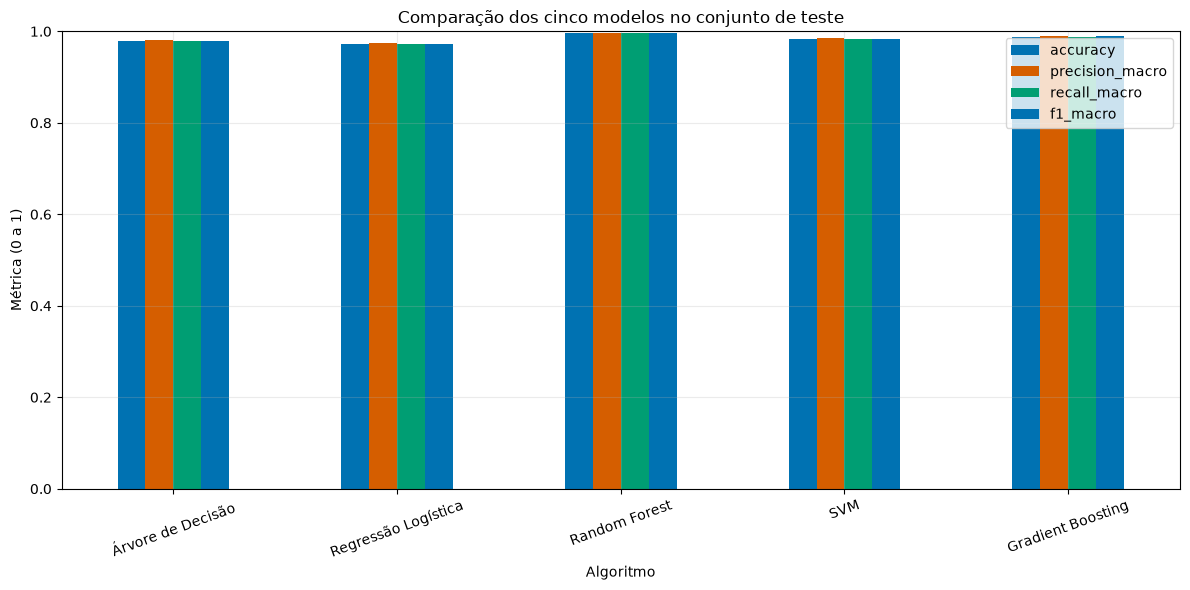

**Maior F1 macro observado no teste:** Random Forest (0.9955). Leia junto aos resultados de CV e ao gap treino-teste. Esta é uma conclusão restrita à partição e ao dataset usados.

In [13]:
resultados_disponiveis = metricas_teste.copy()
tabela_comparacao = criar_tabela_comparacao(resultados_disponiveis)
display(tabela_comparacao[METRICS].sort_values("f1_macro", ascending=False).style.format("{:.4f}"))
fig, ax = plt.subplots(figsize=(12, 6))
tabela_comparacao[METRICS].loc[EXPECTED_MODELS].plot(kind="bar", ylim=(0,1), ax=ax)
ax.set_title("Comparação dos cinco modelos no conjunto de teste")
ax.set_xlabel("Algoritmo"); ax.set_ylabel("Métrica (0 a 1)"); ax.tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

melhor_f1 = tabela_teste["f1_macro"].idxmax()
display(Markdown(f"**Maior F1 macro observado no teste:** {melhor_f1} ({tabela_teste.loc[melhor_f1, 'f1_macro']:.4f}). Leia junto aos resultados de CV e ao gap treino-teste. Esta é uma conclusão restrita à partição e ao dataset usados."))
assert set(resultados_disponiveis) == set(EXPECTED_MODELS)
assert not tabela_comparacao.attrs["modelos_pendentes"]

In [14]:
# Justificativa medida para a escolha e demonstração em um registro real do teste
melhor_modelo = tabela_teste["f1_macro"].idxmax()
cv_f1_melhor = cv_resultados[melhor_modelo]["test_f1_macro"]
gap_melhor = diagnostico.loc[melhor_modelo, "Gap treino − teste"]
display(Markdown(
    f"### Decisão baseada nos resultados\n\n"
    f"**{melhor_modelo}** é selecionado como melhor resultado deste experimento porque obteve o maior "
    f"F1 macro no teste (**{metricas_teste[melhor_modelo]['f1_macro']:.4f}**) e apresentou F1 macro médio "
    f"de **{cv_f1_melhor.mean():.4f}** na validação cruzada, com gap treino-teste de **{gap_melhor:.4f}**. "
    f"Accuracy = {metricas_teste[melhor_modelo]['accuracy']:.4f}, Precision macro = "
    f"{metricas_teste[melhor_modelo]['precision_macro']:.4f} e Recall macro = "
    f"{metricas_teste[melhor_modelo]['recall_macro']:.4f}. Esta escolha vale para este dataset e split; "
    f"não garante superioridade em dados externos."
))

indice_demo = X_test.index[0]
linha_demo = X_test.loc[[indice_demo]]
classe_real_demo = y_test.loc[indice_demo]
classe_prevista_demo = pipelines[melhor_modelo].predict(linha_demo)[0]
print(f"Demonstração — linha real do teste, índice {indice_demo}: classe real={classe_real_demo}; previsão de {melhor_modelo}={classe_prevista_demo}")
display(linha_demo)
assert indice_demo in X_test.index

### Decisão baseada nos resultados

**Random Forest** é selecionado como melhor resultado deste experimento porque obteve o maior F1 macro no teste (**0.9955**) e apresentou F1 macro médio de **0.9931** na validação cruzada, com gap treino-teste de **0.0045**. Accuracy = 0.9955, Precision macro = 0.9957 e Recall macro = 0.9955. Esta escolha vale para este dataset e split; não garante superioridade em dados externos.

Demonstração — linha real do teste, índice 1609: classe real=orange; previsão de Random Forest=orange


,N,P,K,temperature,humidity,ph,rainfall
1609,13,23,6,23.961476,90.26408,7.365338,102.69587


## 10. Conclusões, pontos fortes e limitações

Os dados permitem comparar padrões medidos entre classes e avaliar classificadores com controle de vazamento por meio de pipelines e validação cruzada. O perfil global é apenas referência descritiva.

Os modelos podem reconhecer associações presentes no CSV, mas não provam que as variáveis causam determinada cultura. A base pode não representar regiões, safras, medições ou práticas agrícolas futuras. A Árvore de Decisão e ensembles oferecem importâncias por impureza, que podem favorecer atributos com mais pontos de corte; coeficientes também dependem do pré-processamento e da estrutura multiclasse. Resultados elevados no teste não garantem desempenho externo. A validação com dados independentes e conhecimento agronômico permanece necessária antes de uso operacional.

A recomendação estatística final deve ser interpretada com Accuracy, Precision/Recall/F1 macro, CV, confusões e diferença treino-teste em conjunto; nenhum indicador isolado estabelece superioridade universal.